# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 2 / 1024**2            # 16 bits = 2 bytes per voxel

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)   # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
samples_per_frame = 512 * 300 * 512         # x-z pixels x samples along y
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

1. **Distorted shape:** the voxels are 1.0 mm tall in z but 0.5 mm wide in x and y. If the software shows one voxel as one square pixel, every coronal and sagittal slice is squashed vertically to half its true height (a round lesion looks like a flat ellipse, and the head looks too short).
2. **Wrong measurements:** distances, diameters and volumes read off the screen in pixels would be wrong along z, because one step in z is 1.0 mm and one step in x or y is 0.5 mm. The fix is to display with the aspect ratio z/x (here 2:1) or to resample the volume to isotropic voxels.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

1 components, largest = 431 voxels; centroid (z, y, x) = (28, 40, 41)


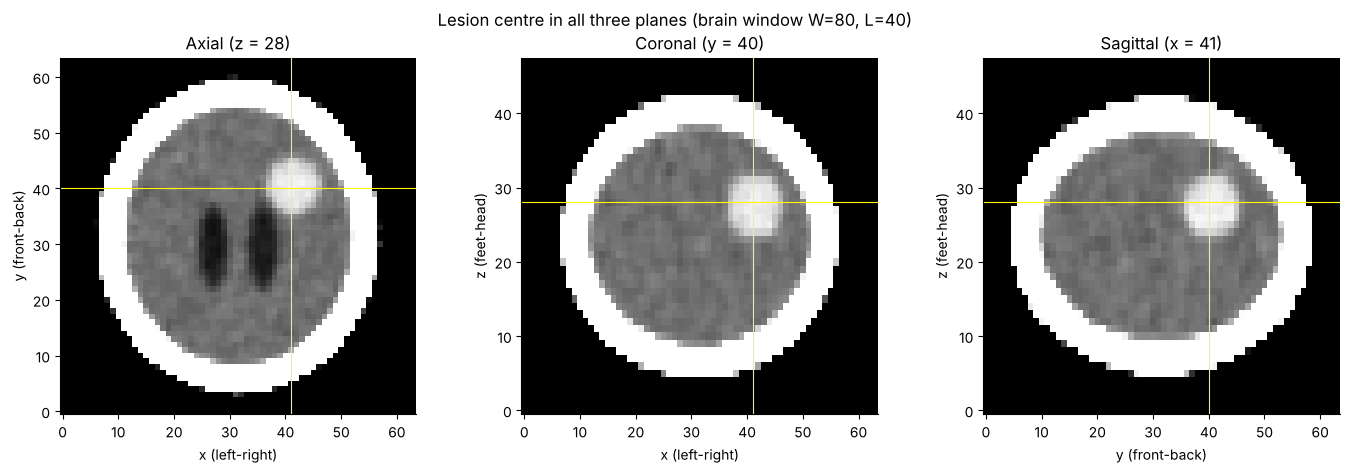

Distance from true tumour centroid: 2.9 mm (truth z,y,x = 27.5, 40.5, 41.5)


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1: candidate lesion voxels (labels NOT used)
bone = vol > 300
inside = ndimage.binary_fill_holes(bone) & ~bone
inside = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside

# TODO 2: largest connected component and its centroid
lab, n = ndimage.label(candidates)
sizes = ndimage.sum(candidates, lab, index=np.arange(1, n + 1))
lesion = lab == (1 + int(np.argmax(sizes)))
cz, cy, cx = [int(round(v)) for v in ndimage.center_of_mass(lesion)]
print(f"{n} components, largest = {int(sizes.max())} voxels; centroid (z, y, x) = ({cz}, {cy}, {cx})")

# TODO 3: three-plane MPR with cross-hairs
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
views = [("Axial (z = %d)" % cz, vol[cz, :, :], "x (left-right)", "y (front-back)", 1.0, (cx, cy)),
         ("Coronal (y = %d)" % cy, vol[:, cy, :], "x (left-right)", "z (feet-head)", ASPECT, (cx, cz)),
         ("Sagittal (x = %d)" % cx, vol[:, :, cx], "y (front-back)", "z (feet-head)", ASPECT, (cy, cz))]
for ax, (title, sl, xl, yl, asp, (px, py)) in zip(axes, views):
    ax.imshow(window(sl, 80, 40), cmap="gray", origin="lower", aspect=asp, vmin=0, vmax=1)
    ax.axvline(px, color="yellow", lw=0.8); ax.axhline(py, color="yellow", lw=0.8)
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl)
fig.suptitle("Lesion centre in all three planes (brain window W=80, L=40)")
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
tz, ty, tx = ndimage.center_of_mass(labels == 5)
err_mm = np.sqrt(((cz - tz) * SPACING[0]) ** 2 + ((cy - ty) * SPACING[1]) ** 2 + ((cx - tx) * SPACING[2]) ** 2)
print(f"Distance from true tumour centroid: {err_mm:.1f} mm (truth z,y,x = {tz:.1f}, {ty:.1f}, {tx:.1f})")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

The skull is much brighter than the brain, so the boundary voxels that are part bone and part brain (and the scalp/air edge) have an *average* intensity: this is the **partial-volume effect**. As a boundary voxel goes from brain (about 35 HU) to bone (over 400 HU) it passes through every intermediate value, including 55-90 HU, which is exactly the tumour range. So the thin shell just under the skull falls into the same intensity range as the tumour; this is the overlapping intensity ranges challenge of Slide 28: one intensity does not identify one material. Eroding the inside-of-skull mask 3 times removes this shell (and noisy voxels at the edge), so only real tissue in the 55-90 HU range remains, and the largest component is then the tumour. Without it, a threshold alone would label the whole shell as lesion.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold_HU,voxels,volume_mL,dice
0,45,535,19.260,0.929
1,50,464,16.704,0.994
2,55,431,15.516,0.963
3,60,350,12.600,0.860
4,65,273,9.828,0.741
5,70,170,6.120,0.536


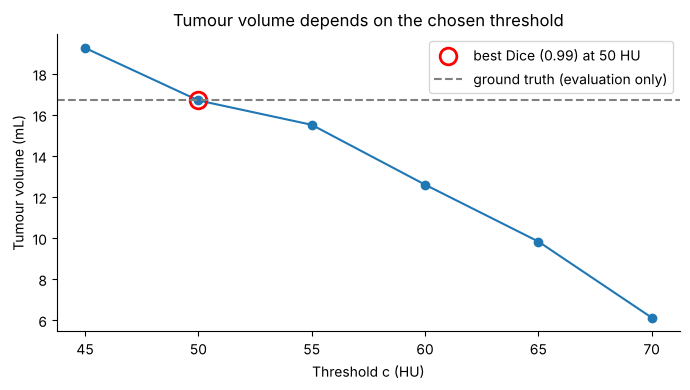

Report to the surgeon: 6.1 - 19.3 mL (thresholds 45-70 HU); best-Dice estimate 16.7 mL at 50 HU; true volume 16.7 mL


In [4]:
truth = labels == 5
rows = []
# TODO 1 & 2
for c in [45, 50, 55, 60, 65, 70]:
    lab_c, _ = ndimage.label(vol > c)
    region = lab_c == lab_c[cz, cy, cx]
    n_vox = int(region.sum())
    dice = 2 * (region & truth).sum() / (region.sum() + truth.sum())
    rows.append({"threshold_HU": c, "voxels": n_vox, "volume_mL": n_vox * VOXEL_MM3 / 1000, "dice": round(float(dice), 3)})

table = pd.DataFrame(rows)
display(table)

# TODO 3
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table.threshold_HU, table.volume_mL, "o-", color="tab:blue")
best = table.loc[table.dice.idxmax()]
ax.plot(best.threshold_HU, best.volume_mL, "o", ms=12, mfc="none", mec="red", mew=2,
        label=f"best Dice ({best.dice:.2f}) at {int(best.threshold_HU)} HU")
ax.axhline(truth.sum() * VOXEL_MM3 / 1000, color="gray", ls="--", label="ground truth (evaluation only)")
ax.set_xlabel("Threshold c (HU)"); ax.set_ylabel("Tumour volume (mL)")
ax.set_title("Tumour volume depends on the chosen threshold"); ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
print(f"Report to the surgeon: {table.volume_mL.min():.1f} - {table.volume_mL.max():.1f} mL "
      f"(thresholds {table.threshold_HU.min()}-{table.threshold_HU.max()} HU); "
      f"best-Dice estimate {best.volume_mL:.1f} mL at {int(best.threshold_HU)} HU; true volume {truth.sum()*VOXEL_MM3/1000:.1f} mL")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

I would choose c by looking at the data rather than by picking one number: draw the volume-versus-threshold curve and pick a threshold in the *plateau* region where the volume changes least, ideally between the mean intensity of the tumour and the mean intensity of the surrounding brain (the half-way value, as in a full-width-half-maximum edge). Here the tumour has about 66 HU and brain about 35 HU, and the curve is flattest around 50-55 HU, which is also where the best Dice was. I would justify it by repeating the measurement with several thresholds (and, ideally, a second observer or algorithm) and agreeing the choice with the radiologist.

To show the uncertainty I would never show a single hard outline or number. I would overlay several nested contours (for example 45, 55 and 65 HU) on the MPR slices, or colour the boundary by the threshold at which it appears, and quote the volume as a range (about 6-19 mL over the full 45-70 HU sweep, and about 15.5-19.3 mL over the plateau 45-55 HU) together with the volume-versus-threshold plot.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

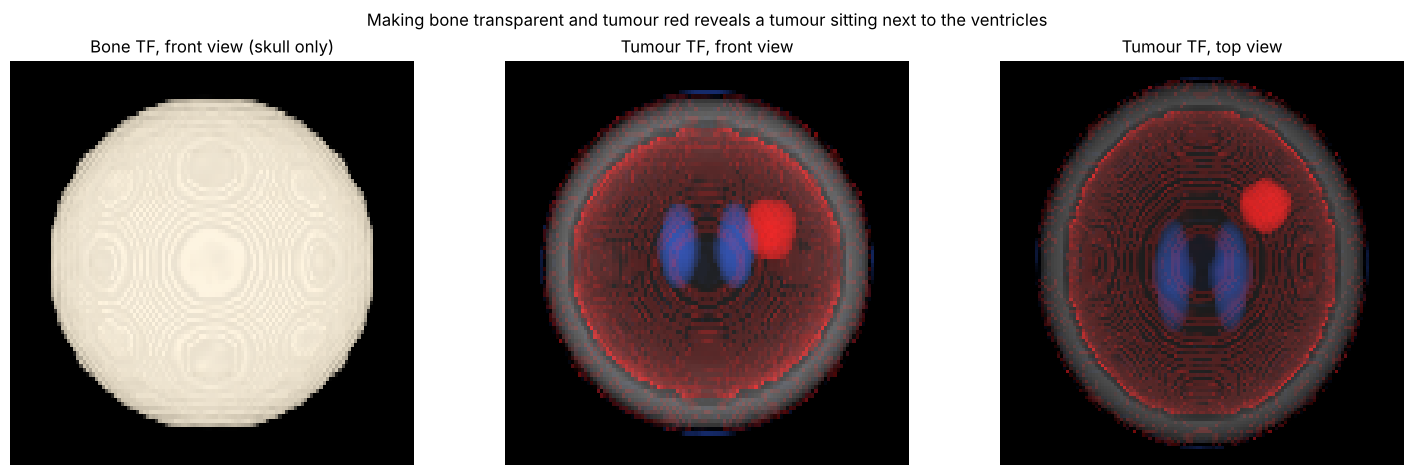

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
# air/soft tissue transparent, bone almost transparent (<=0.01), CSF faint blue, tumour red
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),
    (-20,   (0, 0, 0), 0.0),
    (0,     (0.2, 0.4, 1.0), 0.0),
    (5,     (0.2, 0.4, 1.0), 0.03),     # CSF: faint blue
    (20,    (0.2, 0.4, 1.0), 0.03),
    (25,    (0, 0, 0), 0.0),            # brain (~30-45 HU): transparent
    (58,    (0, 0, 0), 0.0),
    (66,    (1.0, 0.1, 0.1), 0.12),     # tumour: red (thick -> accumulates to opaque)
    (88,    (1.0, 0.1, 0.1), 0.12),
    (96,    (0, 0, 0), 0.0),
    (200,   (0, 0, 0), 0.0),
    (400,   (0.9, 0.9, 0.9), 0.01),     # bone: just a ghost for context
    (1500,  (1, 1, 1), 0.01),
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
def show(ax, tf, axis, title):
    C, A = render(vol, tf, axis=axis)
    img = np.clip(C, 0, 1)            # black background
    ax.imshow(img, origin="lower", aspect=(ASPECT if axis == 1 else 1.0))
    ax.set_title(title); ax.axis("off")
show(axes[0], bone_tf, 1, "Bone TF, front view (skull only)")
show(axes[1], tumour_tf, 1, "Tumour TF, front view")
show(axes[2], tumour_tf, 0, "Tumour TF, top view")

# TODO 4: suptitle
fig.suptitle("Making bone transparent and tumour red reveals a tumour sitting next to the ventricles")
plt.tight_layout(); plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

The faint rim is caused by the **partial-volume / overlapping intensity ranges** challenge of Slide 28: the thin shell between brain and skull passes through the same 60-90 HU values as the tumour, so the transfer function, which only sees the intensity of one sample, gives those samples the tumour colour. Because rays run tangentially through this shell near the silhouette of the head, many samples add up to a visible red rim.

A **segmentation** (as in Task 2: erode the brain mask and keep only the tumour component) or a **gradient/multi-dimensional transfer function** (Slides 31-32) would remove it, by rendering only the voxels that are inside the segmented lesion or only where the gradient shows a real boundary. A transfer function alone cannot do this because it is a function of the single scalar value T(s); it has no idea *where* a voxel is or what its neighbours are, so two voxels with the same HU always get the same colour and opacity.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

**Final note:**

The lesion is a roughly round mass (the centroid is at voxel z = 28, y = 40, x = 41, within 3 mm of the true centre), located on the right side (x axis) of the brain, slightly above mid-height and in the back half, right next to one of the lateral ventricles, and its volume is **about 15.5-19 mL (best estimate about 17 mL at 50 HU)** over the stable thresholds of 45-55 HU. If the threshold is raised to 70 HU the volume falls to about 6 mL, so the number depends strongly on the threshold and should be quoted as a range. I recommend opening the meeting with the **3-plane MPR with the segmentation overlay**: slicing exposes the internal structure without occlusion, and the segmentation is what makes the measurement possible, while the 3-D render can then be used to show the relation to the ventricles. The 3-D render looks convincing, but it should be treated as an illustration, not a measurement: its transfer function is hand-tuned, one intensity can map to several materials (the faint red rim below the skull is an artefact), and the opacity depends on how thick the structure is along each ray, so apparent size and colour are not reliable.